# Experiment 10: Deployment of a Generative AI Application using Gradio / Streamlit

**Aim:** Train a small conditional generative model (a conditional VAE for handwritten digits), package it, and deploy it as
an interactive web application with **Gradio** and with **Streamlit**; test the running apps through their API and a browser.

In [1]:
import os, sys, time, subprocess, urllib.request, textwrap
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import gradio, streamlit
keras.utils.set_random_seed(10)
print("TensorFlow", tf.__version__, "| Gradio", gradio.__version__, "| Streamlit", streamlit.__version__)

I0000 00:00:1792691966.155266    7395 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792691967.378800    7395 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow 2.21.0 | Gradio 6.30.0 | Streamlit 1.66.1


## 1. The model: a conditional VAE
The decoder receives the latent vector $z$ *and* a one-hot digit label, so the app can generate any requested digit.
The size of the latent noise controls the variety of handwriting styles.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")[..., None]
y_oh = keras.utils.to_categorical(y_train, 10).astype("float32")
LAT = 8

class Sampling(layers.Layer):
    def call(self, inp):
        mu, lv = inp; return mu + tf.exp(0.5 * lv) * tf.random.normal(tf.shape(mu))

class KLLoss(layers.Layer):
    """adds the KL divergence of q(z|x) from N(0, I) to the training loss"""
    def call(self, inp):
        mu, lv = inp
        self.add_loss(tf.reduce_mean(-0.5 * tf.reduce_sum(1 + lv - tf.square(mu) - tf.exp(lv), axis=1)))
        return inp

img_in, lab_in = keras.Input((28, 28, 1)), keras.Input((10,))
h = layers.Concatenate()([layers.Flatten()(img_in), lab_in])
h = layers.Dense(256, activation="relu")(h)
mu, lv = KLLoss()([layers.Dense(LAT)(h), layers.Dense(LAT)(h)])
z = Sampling()([mu, lv])
z_in, l_in = keras.Input((LAT,)), keras.Input((10,))
d = layers.Dense(256, activation="relu")(layers.Concatenate()([z_in, l_in]))
d = layers.Dense(784, activation="sigmoid")(d)
decoder = keras.Model([z_in, l_in], layers.Reshape((28, 28, 1))(d), name="digit_decoder")
cvae = keras.Model([img_in, lab_in], decoder([z, lab_in]), name="cvae")
recon_loss = lambda x, xh: tf.reduce_sum(keras.losses.binary_crossentropy(x, xh), axis=(1, 2))
cvae.compile(keras.optimizers.Adam(1e-3), loss=recon_loss)
hist = cvae.fit([x_train, y_oh], x_train, epochs=12, batch_size=128, verbose=2)
decoder.save("digit_decoder.keras")
print("saved model:", os.path.abspath("digit_decoder.keras"), "| size: %.1f KB" % (os.path.getsize("digit_decoder.keras") / 1024))

Epoch 1/12


469/469 - 5s - 10ms/step - loss: 172.2219


Epoch 2/12


469/469 - 3s - 7ms/step - loss: 131.6644


Epoch 3/12


469/469 - 3s - 7ms/step - loss: 124.0184


... (15 outputs left out)

469/469 - 3s - 7ms/step - loss: 109.4934


Epoch 12/12


469/469 - 5s - 10ms/step - loss: 108.8750


saved model: /home/user/GenAI-Lab/_build/exp10/digit_decoder.keras | size: 829.8 KB


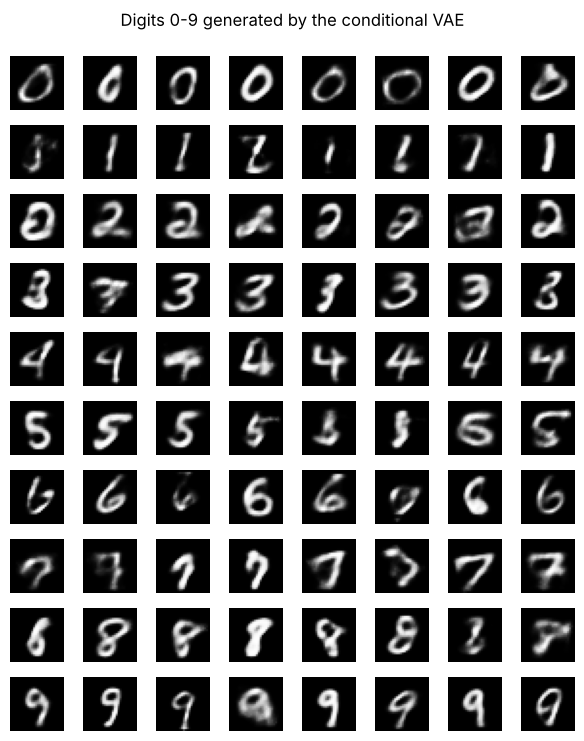

In [3]:
def generate(digit, n=8, variation=1.0, seed=0):
    r = np.random.default_rng(seed)
    z = (variation * r.standard_normal((n, LAT))).astype("float32")
    lab = keras.utils.to_categorical([digit] * n, 10).astype("float32")
    return decoder.predict([z, lab], verbose=0)[..., 0]
fig, axes = plt.subplots(10, 8, figsize=(6, 7.4))
for dgt in range(10):
    for k, im in enumerate(generate(dgt, 8, 1.0, dgt)): axes[dgt, k].imshow(im, cmap="gray"); axes[dgt, k].axis("off")
plt.suptitle("Digits 0-9 generated by the conditional VAE", y=0.995); plt.tight_layout(); plt.show()

## 2. The Gradio application
`gr.Interface` builds a web UI around a Python function: inputs (dropdown, sliders, number) are mapped to the function arguments and
the returned image is displayed. The same file can be deployed on Hugging Face Spaces.

In [4]:
MODEL = os.path.abspath("digit_decoder.keras")
gradio_code = f'''import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, gradio as gr
from tensorflow import keras
from PIL import Image

LAT = {LAT}
decoder = keras.models.load_model(r"{MODEL}", compile=False)

def generate(digit, n_samples, variation, seed):
    rng = np.random.default_rng(int(seed))
    n = int(n_samples)
    z = (variation * rng.standard_normal((n, LAT))).astype("float32")
    lab = keras.utils.to_categorical([int(digit)] * n, 10).astype("float32")
    imgs = decoder.predict([z, lab], verbose=0)[..., 0]
    cols = min(n, 4); rows = -(-n // cols)
    canvas = np.zeros((rows * 28, cols * 28))
    for i, im in enumerate(imgs):
        canvas[(i // cols) * 28:(i // cols + 1) * 28, (i % cols) * 28:(i % cols + 1) * 28] = im
    return Image.fromarray((canvas * 255).astype("uint8")).resize((cols * 112, rows * 112), Image.NEAREST)

demo = gr.Interface(
    fn=generate,
    inputs=[gr.Dropdown(list(range(10)), value=7, label="Digit to generate"),
            gr.Slider(1, 16, value=8, step=1, label="Number of samples"),
            gr.Slider(0.1, 2.0, value=1.0, step=0.1, label="Style variation (latent noise scale)"),
            gr.Number(value=42, label="Random seed")],
    outputs=gr.Image(label="Generated handwriting"),
    title="Handwritten Digit Generator",
    description="A conditional VAE trained on MNIST. Pick a digit and generate new handwriting styles.",
    flagging_mode="never",
)
if __name__ == "__main__":
    demo.launch(server_name="127.0.0.1", server_port=7861)
'''
open("app_gradio.py", "w").write(gradio_code)
print(gradio_code)

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, gradio as gr
from tensorflow import keras
from PIL import Image

LAT = 8
decoder = keras.models.load_model(r"/home/user/GenAI-Lab/_build/exp10/digit_decoder.keras", compile=False)

def generate(digit, n_samples, variation, seed):
    rng = np.random.default_rng(int(seed))
    n = int(n_samples)
    z = (variation * rng.standard_normal((n, LAT))).astype("float32")
    lab = keras.utils.to_categorical([int(digit)] * n, 10).astype("float32")
    imgs = decoder.predict([z, lab], verbose=0)[..., 0]
    cols = min(n, 4); rows = -(-n // cols)
    canvas = np.zeros((rows * 28, cols * 28))
    for i, im in enumerate(imgs):
        canvas[(i // cols) * 28:(i // cols + 1) * 28, (i % cols) * 28:(i % cols + 1) * 28] = im
    return Image.fromarray((canvas * 255).astype("uint8")).resize((cols * 112, rows * 112), Image.NEAREST)

demo = gr.Interface(
    fn=generate,
    inputs=[gr.Dropdown(list(range(10)), value=7, label="Digit to

In [5]:
streamlit_code = f'''import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, streamlit as st
from tensorflow import keras

LAT = {LAT}
st.set_page_config(page_title="Digit Generator", layout="centered")

@st.cache_resource
def load():
    return keras.models.load_model(r"{MODEL}", compile=False)

decoder = load()
st.title("Handwritten Digit Generator (Streamlit)")
st.caption("A conditional VAE trained on MNIST - choose a digit and generate new handwriting styles.")
digit = st.selectbox("Digit to generate", list(range(10)), index=3)
n = st.slider("Number of samples", 1, 16, 8)
variation = st.slider("Style variation", 0.1, 2.0, 1.0, 0.1)
seed = st.number_input("Random seed", value=42, step=1)

if st.button("Generate", type="primary"):
    rng = np.random.default_rng(int(seed))
    z = (variation * rng.standard_normal((n, LAT))).astype("float32")
    lab = keras.utils.to_categorical([digit] * n, 10).astype("float32")
    imgs = decoder.predict([z, lab], verbose=0)[..., 0]
    st.image(list(imgs), width=100, clamp=True)
    st.success(f"Generated {{n}} images of the digit {{digit}}")
'''
open("app_streamlit.py", "w").write(streamlit_code)
print("app_streamlit.py written:", len(streamlit_code.splitlines()), "lines")

app_streamlit.py written: 27 lines


## 3. Launching and testing the Gradio app

In [6]:
env = dict(os.environ, NO_PROXY="127.0.0.1,localhost", no_proxy="127.0.0.1,localhost")
gproc = subprocess.Popen([sys.executable, "app_gradio.py"], env=env, stdout=open("gradio.log", "w"), stderr=subprocess.STDOUT)
def wait_for(url, timeout=120):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            r = urllib.request.urlopen(url, timeout=2); return r.status, time.time() - t0
        except Exception: time.sleep(1)
    return None, timeout
status, secs = wait_for("http://127.0.0.1:7861/")
print(f"Gradio server on http://127.0.0.1:7861 -> HTTP {status} after {secs:.1f}s")

Gradio server on http://127.0.0.1:7861 -> HTTP 200 after 6.0s


Client.predict() Usage Info
---------------------------
Named API endpoints: 1

 - predict(digit, n_samples, variation, seed, api_name="/generate") -> generated_handwriting
    Parameters:
     - [Dropdown] digit: Literal['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'] (not required, defaults to:   7)  
     - [Slider] n_samples: float (not required, defaults to:   8)  
     - [Slider] variation: float (not required, defaults to:   1.0)  
     - [Number] seed: float (not required, defaults to:   42)  
    Returns:
     - [Image] generated_handwriting: filepath 

API endpoints: ['/generate']


request answered in 0.25s -> image.webp
returned image: (448, 224) RGB


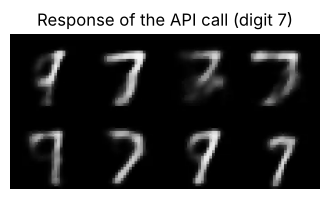

In [7]:
from gradio_client import Client
from PIL import Image
client = Client("http://127.0.0.1:7861", verbose=False)
print("API endpoints:", [k for k in client.view_api(return_format="dict")["named_endpoints"]])
t0 = time.time()
path = client.predict(7, 8, 1.0, 42, api_name="/generate")
print(f"request answered in {time.time() - t0:.2f}s -> {os.path.basename(path)}")
img = Image.open(path); print("returned image:", img.size, img.mode)
plt.figure(figsize=(4, 2.4)); plt.imshow(img, cmap="gray"); plt.axis("off"); plt.title("Response of the API call (digit 7)"); plt.show()

## 4. Launching and testing the Streamlit app

In [8]:
sproc = subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app_streamlit.py", "--server.port", "8601", "--server.headless", "true",
                          "--browser.gatherUsageStats", "false"], env=env, stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
status, secs = wait_for("http://127.0.0.1:8601/_stcore/health")
print(f"Streamlit server on http://127.0.0.1:8601 -> health check HTTP {status} after {secs:.1f}s")

Streamlit server on http://127.0.0.1:8601 -> health check HTTP 200 after 1.0s


## 5. Browser screenshots of both running apps
A headless Chromium (Playwright) opens each application, fills the form and clicks the button, as a user would.

In [9]:
shot_code = r'''
import sys, glob
from playwright.sync_api import sync_playwright
exe = glob.glob("/opt/pw-browsers/chromium-*/chrome-linux*/chrome")[0]
which = sys.argv[1]
with sync_playwright() as p:
    b = p.chromium.launch(executable_path=exe, args=["--no-proxy-server", "--no-sandbox"])
    pg = b.new_page(viewport={"width": 1100, "height": 640})
    if which == "gradio":
        pg.goto("http://127.0.0.1:7861/"); pg.wait_for_selector("text=Handwritten Digit Generator", timeout=60000)
        pg.get_by_role("button", name="Submit").click(); pg.wait_for_selector("img[src*='file=']", timeout=60000)
        pg.wait_for_timeout(1500); pg.screenshot(path="screenshot_gradio.png")
    else:
        pg.goto("http://127.0.0.1:8601/"); pg.wait_for_selector("text=Handwritten Digit Generator", timeout=90000)
        pg.get_by_role("button", name="Generate").click(); pg.wait_for_selector("text=Generated 8 images", timeout=60000)
        pg.wait_for_timeout(1500); pg.screenshot(path="screenshot_streamlit.png", full_page=True)
    b.close()
'''
open("shot.py", "w").write(shot_code)
print("shot.py written")

shot.py written


exit code: 0 


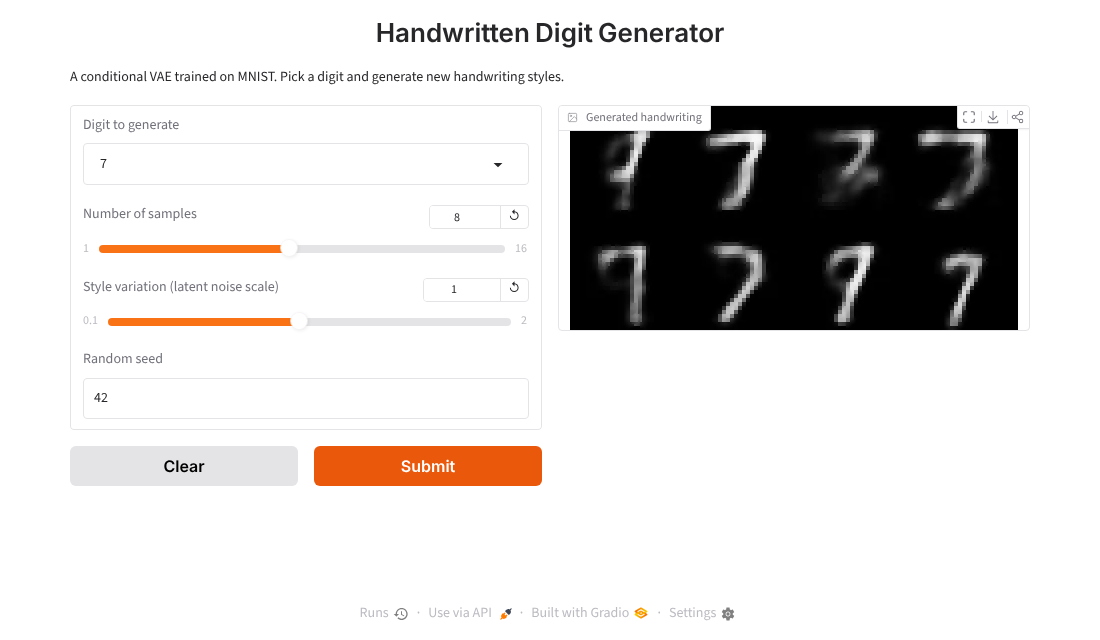

In [10]:
r = subprocess.run([sys.executable, "shot.py", "gradio"], env=env, capture_output=True, text=True, timeout=180)
print("exit code:", r.returncode, r.stderr[-300:])
from IPython.display import Image as IPImage, display
display(IPImage("screenshot_gradio.png", width=900))

exit code: 0 


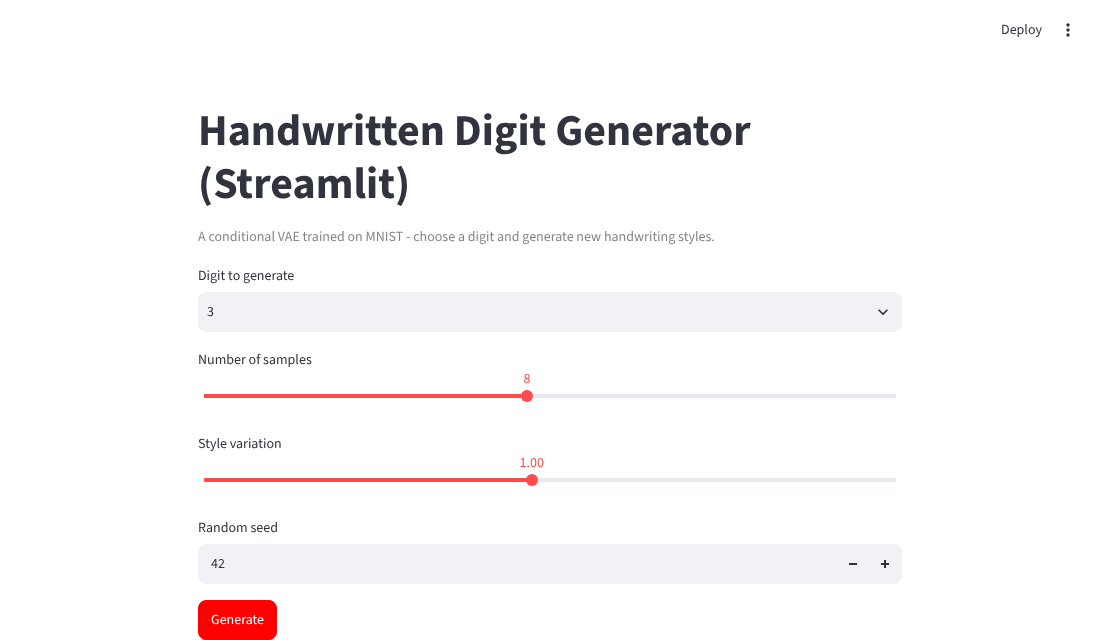

In [11]:
r = subprocess.run([sys.executable, "shot.py", "streamlit"], env=env, capture_output=True, text=True, timeout=240)
print("exit code:", r.returncode, r.stderr[-300:])
display(IPImage("screenshot_streamlit.png", width=900))

In [12]:
for proc in (gproc, sproc): proc.terminate()
time.sleep(2)
print("Gradio server exit code :", gproc.poll())
print("Streamlit server exit code:", sproc.poll())
print("Deployment files:", [f for f in ("digit_decoder.keras", "app_gradio.py", "app_streamlit.py") if os.path.exists(f)])
print("\nTo deploy publicly: push app_gradio.py + model + requirements.txt to a Hugging Face Space (SDK: Gradio) or Streamlit Community Cloud.")

Gradio server exit code : -15
Streamlit server exit code: 0
Deployment files: ['digit_decoder.keras', 'app_gradio.py', 'app_streamlit.py']

To deploy publicly: push app_gradio.py + model + requirements.txt to a Hugging Face Space (SDK: Gradio) or Streamlit Community Cloud.
